<div style="display: flex; background-color: RGB(0,57,230);" >
<h1 style="margin: auto; padding: 30px; color:white; ">ANALYSER LES PICS DE VENTE ANNUELS POUR GERER AU MIEUX LES VARIATIONS D ACTIVITES</h1>
</div>

#### Contexte
FastAlim, entreprise spécialisée dans la fourniture de produits alimentaires et de boissons aux professionnels de la restauration, en tant que Supply Chain Data Analyste je suis chargé d'analyser les ventes de fruits et légumes frais.

FastAlim souhaite développer cette activité, identifiée comme un levier de croissance. Cette évolution nécessite d'anticiper les variations de l'activité afin d'adapter l'organisation logistique et la gestion des stocks.

L'étude porte sur les **quatre dernières années de données disponibles**, soit la période **2019–2022**

#### Problématique
**Comment l'analyse de l'évolution et de la saisonnalité des ventes de fruits et légumes peut-elle permettre à FastAlim d'anticiper les variations d'activité et d'optimiser la répartition des produits dans l'entrepôt ?**

#### Objectifs de l'analyse
Cette étude a pour objectifs de :
- explorer et préparer les données de ventes ;
- identifier les produits les plus importants sur les quatre dernières années ;
- identifier le **top 5 des produits** ;
- analyser leur évolution annuelle et mensuelle ;
- identifier les éventuels **pics et creux saisonniers** ;
- comparer les comportements des produits du top 5 ;
- analyser les **corrélations entre leurs évolutions** ;
- identifier les produits présentant des saisonnalités similaires ou complémentaires ;
- proposer des **recommandations de répartition du stock dans l'entrepôt** à partir des résultats obtenus.

# Sommaire

#### 1. Explorez le jeu de données
- [1.1 Chargez les données]
- [1.2 Déterminez les ordres de grandeur et indicateurs statistiques basiques]
- [1.3 Préparez le jeu de données pour l analyse]

#### 2. Analysez les saisonnalités du top 5 des produits
- [2.1 Visualisez les données]
- [2.2 Sélectionnez le top 5]
- [2.3 Analysez les ventes annuelles par produit]
- [2.4 Analysez les ventes mensuelles par produit]

#### 3. Analysez les corrélations et les similarités de saisonnalité entre les produits du top 5
- [3.1 Distribution annuelle des volumes de ventes des top 5 produits]
- [3.2 Distribution mensuelle des volumes de ventes des top 5 produits]
- [3.3 Analyse des corrélations]
- [3.4 Graphiques complémentaires]
- [3.5 Conclusion et recommandations de répartition en entrepôt]

# P10 - Analysez les saisonnalités des ventes d'une activité e-commerce pour gérer au mieux les variations d'activité

## 1/ Explorez le jeu de données

### Importation des librairies

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import scipy.stats as st
import os

## 1.1 Chargez les données

In [2]:
dataset=pd.read_excel("Jeu+de+donnees_P9_SCA.xlsx")

In [3]:
os.getcwd()

'C:\\Users\\Zooty\\OneDrive\\Bureau\\Jupyter_notebook\\Projet_9_analyse_pics_de_vente_annuels'

## 1.2 Déterminez les ordres de grandeurs et indicateurs statistiques basiques

### Affichez les premièrs et dernières lignes du jeu de données

In [4]:
print("\nPremières lignes du jeu de données:\n")
display(dataset.head())
print("\nDernières lignes du jeu de données:\n")
display(dataset.tail())


Premières lignes du jeu de données:



,date,product,sales
0,2017-01-01,tomate,121.629409
1,2017-01-02,tomate,118.254860
2,2017-01-03,tomate,115.894564
3,2017-01-04,tomate,112.591428
4,2017-01-05,tomate,105.016703



Dernières lignes du jeu de données:



,date,product,sales
32860,2022-12-27,mangue,44.855785
32861,2022-12-28,mangue,39.626589
32862,2022-12-29,mangue,42.041256
32863,2022-12-30,mangue,43.909817
32864,2022-12-31,mangue,44.583940


Les données semble aller de janvier 2017 à décembre 2022. information à confirmer quand les données seront correctement trié par date

In [5]:
#Vérification des dates du dataframe
dataset["date"].min()
dataset["date"].max()
print("la date minimale est:" ,dataset["date"].min())
print("la date maximale est:" ,dataset["date"].max())

la date minimale est: 2017-01-01 00:00:00
la date maximale est: 2022-12-31 00:00:00


### Déterminez la structure du jeu de données

In [6]:
dataset.shape[0]
dataset.shape[1]
print("il y a",dataset.shape[1],"variables" " et", dataset.shape[0],"observations.")

il y a 3 variables et 32865 observations.


In [7]:
dataset.dtypes

date       datetime64[us]
product               str
sales             float64
dtype: object

In [8]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 32865 entries, 0 to 32864
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     32865 non-null  datetime64[us]
 1   product  32865 non-null  str           
 2   sales    32865 non-null  float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 977.9 KB


### Traitez les valeurs manquantes

In [9]:
dataset.isnull().sum()

date       0
product    0
sales      0
dtype: int64

Il n'y a pas de valeurs manquantes

In [10]:
# Je contrôle également si il existe des lignes dupliquées
dataset.duplicated().any()

np.False_

In [11]:
dataset[dataset["sales"]<0]

,date,product,sales
17995,2018-04-13,orange,-0.382452
28596,2017-04-24,pamplemousse,-3.789978


Deux observations avec des prix négatifs, potentiellement incohérentes, une investigation est nécessaire

In [12]:
#je cherche les obervations dont le produit est orange et dont la date est comprise entre le 10 et 16 avril. je compare les deux lignes négatives à des
#obervations comparables (même produit sur période proche)
print("\nObservations sur product: orange\n")
display(
dataset[
(dataset["product"]=="orange")&(dataset["date"]>="2018-04-10")&(dataset["date"]<="2018-04-16")
    ]
)
print("\nObservations sur product:pamplemousse\n")
display(
dataset[
(dataset["product"]=="pamplemousse")&(dataset["date"]>="2017-04-21")&(dataset["date"]<="2017-04-27")
    ]
)


Observations sur product: orange



,date,product,sales
17992,2018-04-10,orange,136.565620
17993,2018-04-11,orange,75.578528
17994,2018-04-12,orange,76.536246
17995,2018-04-13,orange,-0.382452
17996,2018-04-14,orange,56.160451
17997,2018-04-15,orange,46.249816
17998,2018-04-16,orange,54.319334



Observations sur product:pamplemousse



,date,product,sales
28593,2017-04-21,pamplemousse,53.025437
28594,2017-04-22,pamplemousse,100.923521
28595,2017-04-23,pamplemousse,97.911021
28596,2017-04-24,pamplemousse,-3.789978
28597,2017-04-25,pamplemousse,83.989835
28598,2017-04-26,pamplemousse,68.303464
28599,2017-04-27,pamplemousse,26.811276


In [13]:
#J'ai vérifié le contexte temporel de ces lignes, elles sont bien différentes des observations voisines. Je les supprime car il n'y a pas d'impact métier conséquent
#incohérence métier et faible nombre d'observation concernées (peux d'impact sur l'analyse)
dataset=dataset[dataset["sales"]>0]

In [14]:
dataset[dataset["sales"]<0]#je vérifie que la commande a été prise en compte

,date,product,sales


### Calculez des indicateurs statistiques

In [15]:
dataset.describe(include='all')

,date,product,sales
count,32863,32863,32863.000000
unique,NaN,15,NaN
top,NaN,tomate,NaN
freq,NaN,2191,NaN
mean,2020-01-01 01:10:32.845449,NaN,97.123895
min,2017-01-01 00:00:00,NaN,0.983815
25%,2018-07-02 00:00:00,NaN,69.910876
50%,2020-01-01 00:00:00,NaN,91.857408
75%,2021-07-02 00:00:00,NaN,122.167161
max,2022-12-31 00:00:00,NaN,228.911753


In [16]:
# Calcul de la variance
dataset["sales"].var()

np.float64(1408.3144557804408)

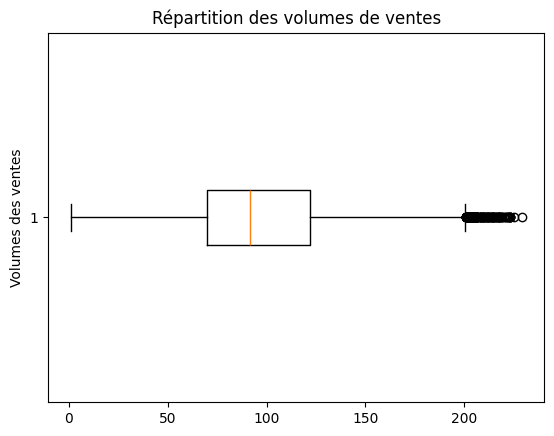

In [17]:
plt.boxplot(dataset["sales"], vert=False)
plt.title("Répartition des volumes de ventes")
plt.ylabel("Volumes des ventes")
plt.show()

Le jeu de données contient 32 865 observations réparties entre 15 produits distincts. La tomate est le produit qui apparaît le plus fréquemment dans le dataset, avec 2 191 observations.
La valeur moyenne de "sales" est d'environ 97,12€ sur l'ensemble des observations. 50% des observations ont une valeur<=91,85€ et 50% ont une valeur >=91,85€
l'écart-type de 37,53 mesure la dispersion des observations autour de la moyenne. 25%  (Q1;premier quartile) des observations ont une valeur de "sales" inférieure
ou égale à environ 69,90€ et à l'inverse, 75% des observations sont inférieure ou égale 122,16€.
L’IQR est de 52,25 € ça signifie que 50 % des observations de "sales" sont comprises entre 69,91 € (Q1) et 122,16 € (Q3), l’IQR mesure la dispersion de ces 50 % d’observations autour de la médiane.

## 1.3 Préparez le jeu de données pour l'analyse

Je créer les variables année et mois afin de faciliter les agrégations temporelles qui serviront à analyer les saisonnalités;
Et je vérifie le résultat puis le type pour les nouvelles colonnes.

In [15]:
dataset["year"] = dataset["date"].dt.year

In [16]:
dataset["month"] = dataset["date"].dt.month

In [17]:
display(dataset.head())

,date,product,sales,year,month
0,2017-01-01,tomate,121.629409,2017,1
1,2017-01-02,tomate,118.254860,2017,1
2,2017-01-03,tomate,115.894564,2017,1
3,2017-01-04,tomate,112.591428,2017,1
4,2017-01-05,tomate,105.016703,2017,1


In [18]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 32865 entries, 0 to 32864
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     32865 non-null  datetime64[us]
 1   product  32865 non-null  str           
 2   sales    32865 non-null  float64       
 3   year     32865 non-null  int32         
 4   month    32865 non-null  int32         
dtypes: datetime64[us](1), float64(1), int32(2), str(1)
memory usage: 1.2 MB


# 2/ Analysez les saisonnalités du top 5 des produits et les corrélations

## 2.1 Visualisez les données

Première vue d'ensemble des données, évolution des volumes de ventes de l'ensemble des produits au cours du temps.

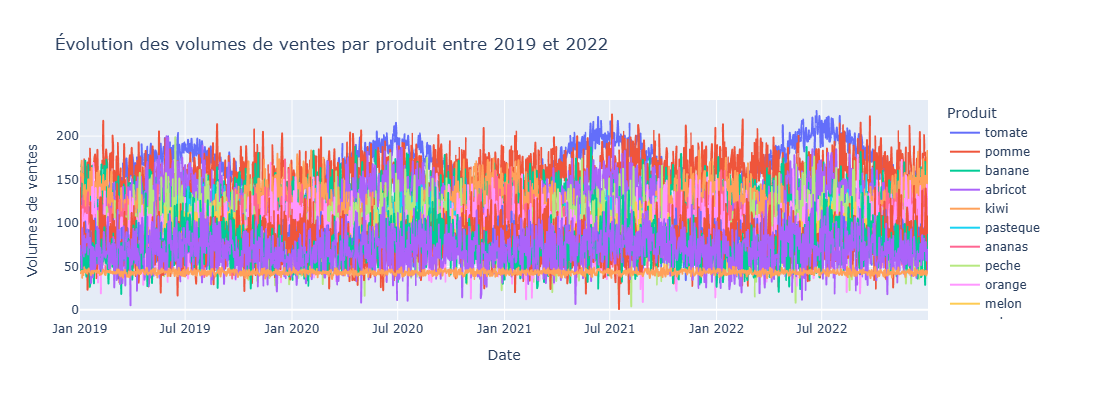

In [121]:
fig = px.line(
    dataset_4ans,
    x="date",
    y="sales",
    color="product",
    title="Évolution des volumes de ventes par produit entre 2019 et 2022"
)
fig.update_xaxes(title_text="Date")
fig.update_yaxes(title_text="Volumes de ventes")
fig.update_layout(
    legend_title_text="Produit",
    height=400,
    width=800
)
fig.show()

## 2.2 Sélectionnez le top 5

In [44]:
#Etape 1/ le cahier des charges impose une analyse sur les 4 dernières années, il faut donc restreindre le périmètre. Je créer alors une variable sur ces dates.
dataset_4ans=dataset[
    (dataset["year"]>=2019)&(dataset["year"]<=2022)
]
print(dataset_4ans["date"].min())
print(dataset_4ans["date"].max())

2019-01-01 00:00:00
2022-12-31 00:00:00


In [45]:
top5_produits = (
    dataset_4ans
    .groupby("product", as_index=False)["sales"]
    .sum()
    .sort_values("sales", ascending=False)
    .head(5)
)
display(top5_produits)

,product,sales
14,tomate,238205.130585
13,pomme,225451.236110
2,banane,188235.306333
0,abricot,178763.877698
5,kiwi,171136.625422


## 2.3 Analysez les ventes annuelles par produit

In [50]:
dataset_top5=dataset_4ans[
dataset_4ans["product"].isin(["tomate", "pomme", "banane", "abricot", "kiwi"])
    ]

In [51]:
display(dataset_top5.head(5))

,date,product,sales,year,month
730,2019-01-01,tomate,128.886021,2019,1
731,2019-01-02,tomate,121.186127,2019,1
732,2019-01-03,tomate,129.488484,2019,1
733,2019-01-04,tomate,111.826799,2019,1
734,2019-01-05,tomate,121.213047,2019,1


In [53]:
top5_annuel=(
dataset_top5
    .groupby(["year", "product"], as_index=False)["sales"]
    .sum()
)

In [55]:
display(top5_annuel.head(10))

,year,product,sales
0,2019,abricot,44899.938757
1,2019,banane,46891.231939
2,2019,kiwi,42444.064781
3,2019,pomme,54465.614811
4,2019,tomate,56575.572140
5,2020,abricot,44878.135424
6,2020,banane,47481.644020
7,2020,kiwi,42874.738564
8,2020,pomme,55673.797519
9,2020,tomate,58553.414693


In [56]:
#avant de construire le graphique matplotlib je construis les tableaux intermédiaires (sous dataframmes)
tomate=top5_annuel[top5_annuel["product"]=="tomate"]
abricot=top5_annuel[top5_annuel["product"]=="abricot"]
banane=top5_annuel[top5_annuel["product"]=="banane"]
kiwi=top5_annuel[top5_annuel["product"]=="kiwi"]
pomme=top5_annuel[top5_annuel["product"]=="pomme"]

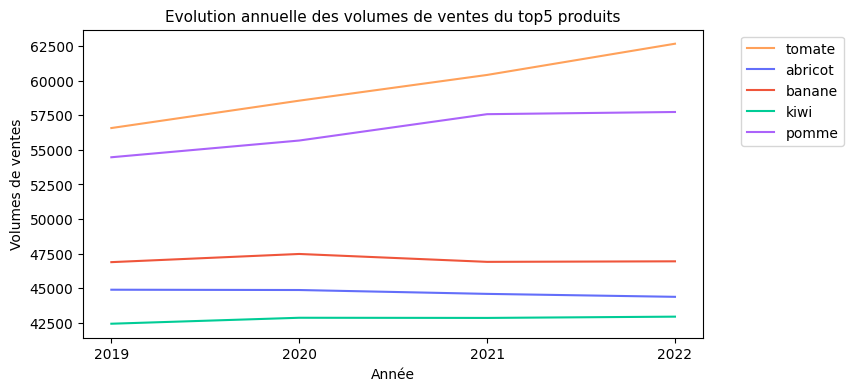

In [179]:
plt.figure(figsize=(8, 4))

plt.plot(tomate["year"], tomate["sales"], label="tomate", color="#FFA15A")
plt.plot(abricot["year"], abricot["sales"], label="abricot", color="#636EFA")
plt.plot(banane["year"], banane["sales"], label="banane", color="#EF553B")
plt.plot(kiwi["year"], kiwi["sales"], label="kiwi", color="#00CC96")
plt.plot(pomme["year"], pomme["sales"], label="pomme", color="#AB63FA")

plt.title("Evolution annuelle des volumes de ventes du top5 produits", fontsize=11)
plt.xlabel("Année")
plt.ylabel("Volumes de ventes")
plt.xticks([2019, 2020, 2021, 2022])

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

Observations: 3 comportements distincts
1-la tomate avec une croissance régulière sur les 4 années on passe de 56K de volumes en 2019 à 62K en 2022, c'est le seul produit avec des volumes aussi élevés.
2-même chose pour la pomme croissance régulière on passe de 54K de volumes à 57k entre 2019 et 2021 puis stabilité en 2022 encore 57k.
2-les autres produits (banane,abricot et kiwi) ont des volumes stables autour de 42K et 44K sur les 4 ans. La banane connait toutefois une légère hausse en 2020, 47K, suivi d'une légère baisse en 2021, 46k puis stabilisation en 2022.
Cette analyse permet d'identifier une tendance annuelles du top5 des produits mais ne permet pas une analyse de saisonnalité. il faut une analyse de granularité mensuelle.

## 2.4 Analysez les ventes mensuelles par produit

In [84]:
dataset_top5["month_year"] = dataset_top5["date"].dt.to_period("M")
dataset_top5["month_year"] = dataset_top5["month_year"].astype(str)

top5_mensuel=(
dataset_top5
    .groupby(["month_year", "product"], as_index=False)["sales"]
    .sum()
)
display(top5_mensuel.head(10))

,month_year,product,sales
0,2019-01,abricot,3272.588851
1,2019-01,banane,4188.782050
2,2019-01,kiwi,4284.851462
3,2019-01,pomme,4707.635702
4,2019-01,tomate,3956.441344
5,2019-02,abricot,3200.013270
6,2019-02,banane,3858.469044
7,2019-02,kiwi,3826.777960
8,2019-02,pomme,4286.574129
9,2019-02,tomate,3782.131231


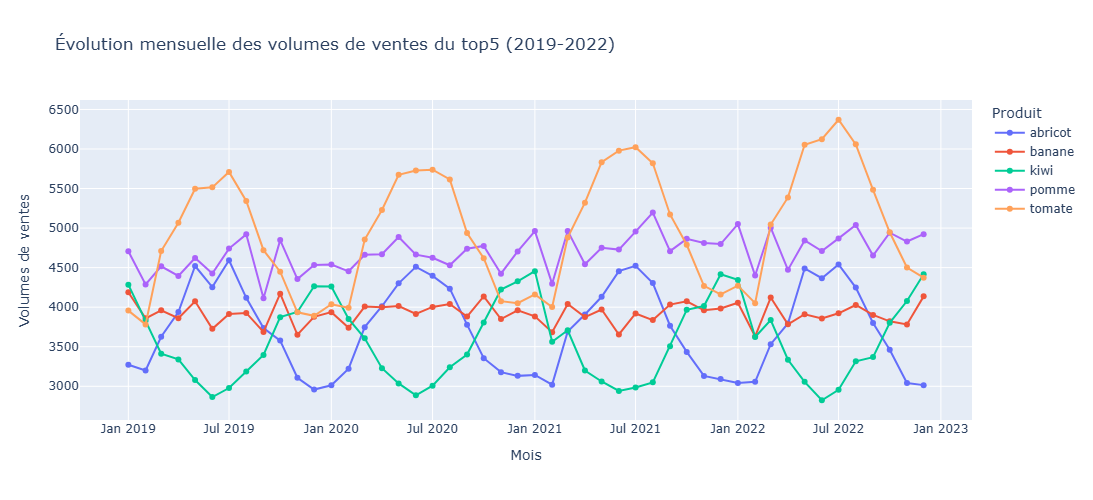

In [92]:
fig = px.line(
    data_frame=top5_mensuel,
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    title="Évolution mensuelle des volumes de ventes du top5 (2019-2022)"
)
fig.update_xaxes(
    title_text="Mois"
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    legend_title_text="Produit",
    width=900,
    height=500
)
fig.show()

In [103]:
#affiche la liste des codes palette de couleur plotly Express
px.colors.qualitative.Plotly

['#636EFA',
 '#EF553B',
 '#00CC96',
 '#AB63FA',
 '#FFA15A',
 '#19D3F3',
 '#FF6692',
 '#B6E880',
 '#FF97FF',
 '#FECB52']

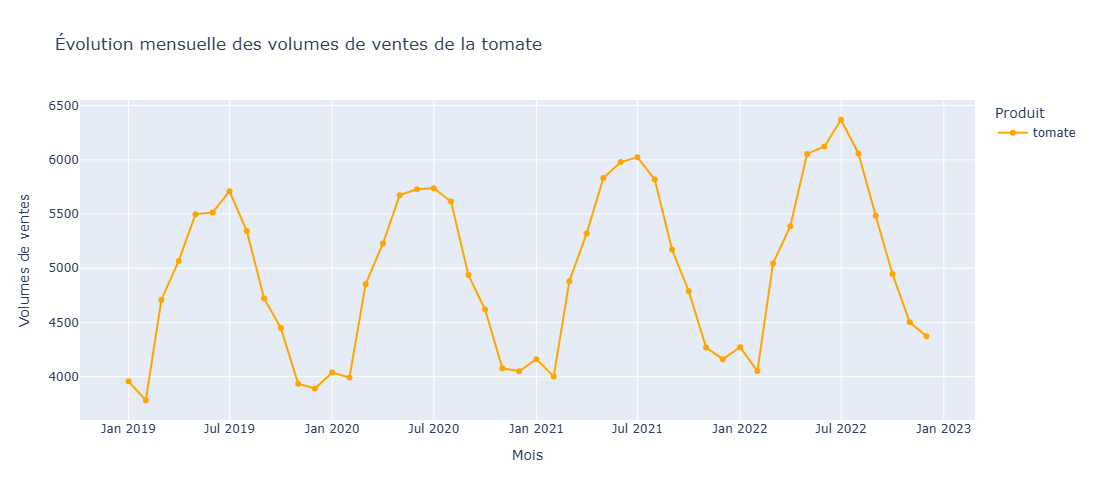

In [96]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"] == "tomate"],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_sequence=["orange"],
    title="Évolution mensuelle des volumes de ventes de la tomate"
)
fig.update_xaxes(
    title_text="Mois"
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    legend_title_text="Produit",
    width=900,
    height=500
)
fig.show()

On observe une croissance progressive des volumes de ventes on passe de 5500 à 6400 entre 2019 et 2022.
Saisonnalité marquée et régulière pour la tomate sur les 4 ans. Les volumes de ventes augmentent à partir de mars (printemps) pour atteindre leur niveau max en juillet-août puis diminuent progressivement pour atteindre leur niveau le plus bas en hiver. Ce cycle se répète chaque année. Pics: juillet 2019. Janvier et juillet 2020. Janvier et juillet 2021. Janvier et juillet 2022
Creux: février et décembre 2019. Février et décembre 2020. Février et décembre 2021. Février 2022.

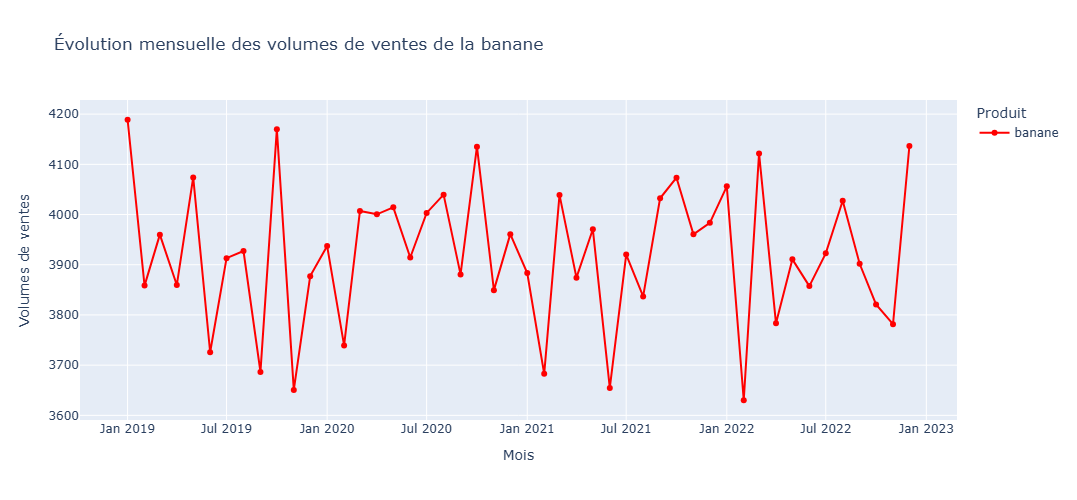

In [100]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"] == "banane"],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_sequence=["red"],
    title="Évolution mensuelle des volumes de ventes de la banane"
)
fig.update_xaxes(
    title_text="Mois"
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    legend_title_text="Produit",
    width=900,
    height=500
)
fig.show()

Les volumes de la banane présentent une légère hausse on passe de 4000 et 4200 sur les 4 ans.
La saisonnalité pour ce produit, est plus difficile à identifier visuellement comparé à celle observée pour la tomate car les pics et les creux varient davantage d'une année à l'autre. Pics observés en mars, mai, août et octobre 2019 puis janvier, mars, mai, août, octobre et décembre 2020. Mars, mai, juillet et octobre 2021. Janvier, mars, mai et août 2022. Creux: février, avril, juin, septembre et novembre 2019. Février, juin, septembre et novembre 2020. Février, avril, juin, août et novembre 2021. Février, avril, juin et novembre 2022. Mais certaines régularités apparaissent tout de même sur les 4 ans. Le mois de mars est un pic récurrent sur les 4 ans et février, juin et novembre sont des creux récurrents sur les 4 ans. 

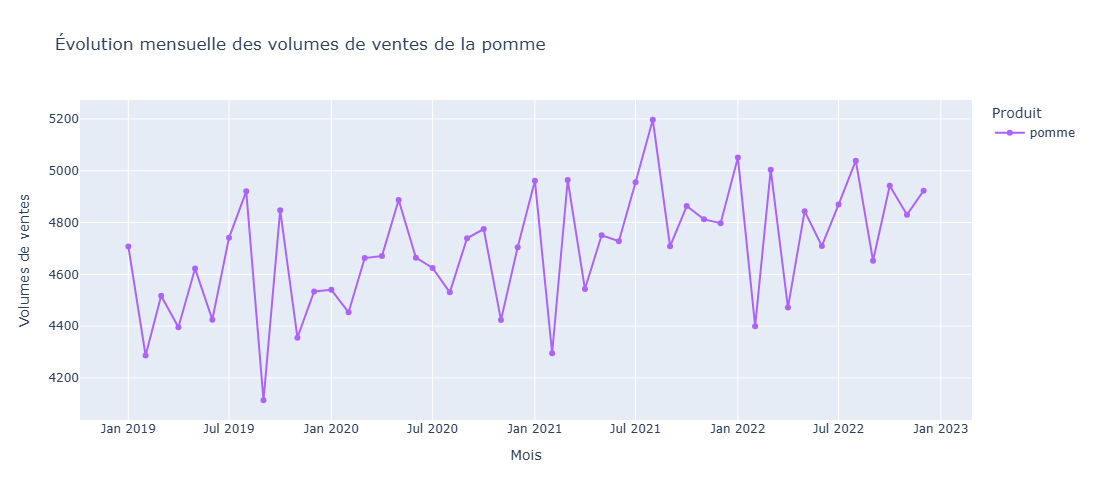

In [108]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"] == "pomme"],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_sequence=["#AB63FA"],
    title="Évolution mensuelle des volumes de ventes de la pomme"
)
fig.update_xaxes(
    title_text="Mois"
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    legend_title_text="Produit",
    width=900,
    height=500
)
fig.show()

Volumes des pommes présentent une légère hausse de 4700 à 4900 sur les 4 ans, un pic observé en août 2021 avec un volume proche de 5200.
Saisonnalité moins marquée, plutot irrégulière: pics: mars, mai, août et octobre 2019. Janvier, mai et octobre 2020. Janvier, mars, mai, août et octobre 2021. Janvier, mars, mai, août et octobre 2022. Creux: février, avril, juin, septembre et novembre 2019. Février, avril, août et novembre 2020. Février, avril, juin, septembre et décembre 2021. Février, avril, juin, septembre et novembre 2022. Mais comme la banane certaines périodes se répètent: mai et octobre sont des pics récurrents et février et avril correspondent à des creux récurrents.

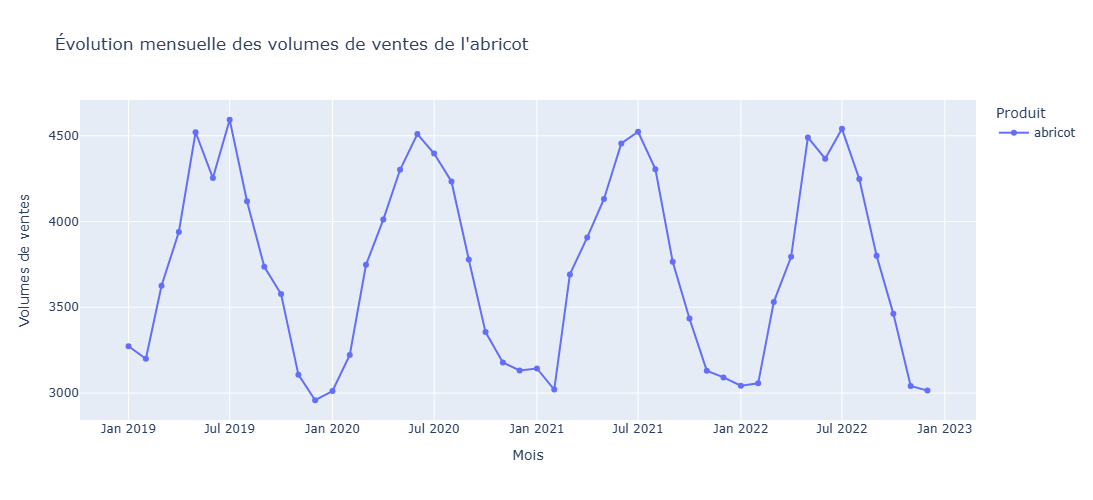

In [109]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"] == "abricot"],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_sequence=["#636EFA"],
    title="Évolution mensuelle des volumes de ventes de l'abricot"
)
fig.update_xaxes(
    title_text="Mois"
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    legend_title_text="Produit",
    width=900,
    height=500
)
fig.show()

Graphique plus simple à interpréter comparé à banane, pomme. Pour les volumes des abricot pas de tendance nette à la hausse ou à la baisse, de manière générale mais saisonnalité marquée, les volumes de ventes pour augmentent principalement entre mai et juillet, pic récurrent en juin.
On observe des creux généralement en début d'année (janvier/février) et fin d'année (novembre/décembre). Comportement qui se répéte sur les 4 années. 

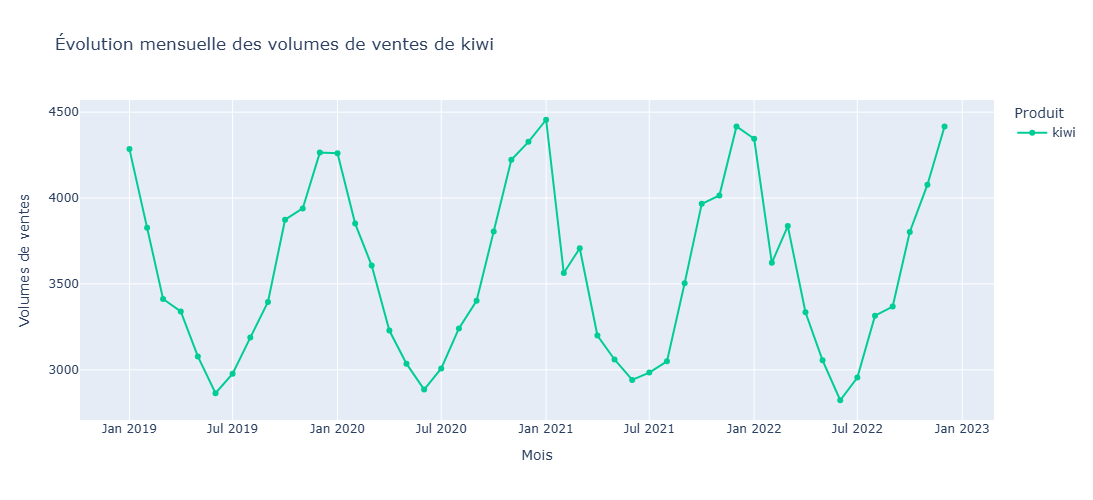

In [118]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"] == "kiwi"],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_sequence=["#00CC96"],
    title="Évolution mensuelle des volumes de ventes de kiwi"
)
fig.update_xaxes(
    title_text="Mois"
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    legend_title_text="Produit",
    width=900,
    height=500
)
fig.show()

Volumes des ventes globalement stables pour le kiwi mais une saisonnalité très marquée
pics: en fin et début d'année autour de décembre et janvier (hiver). Niveau le plus bas en juin et juillet (été) et ce cycle se répètent régulièrement sur les 4 ans. 

# 3/ Analysez les corrélations et les similarités de saisonnalité entre les produits du top 5

### 3.1 Distribution annuelles des volumes de ventes des top 5 produits

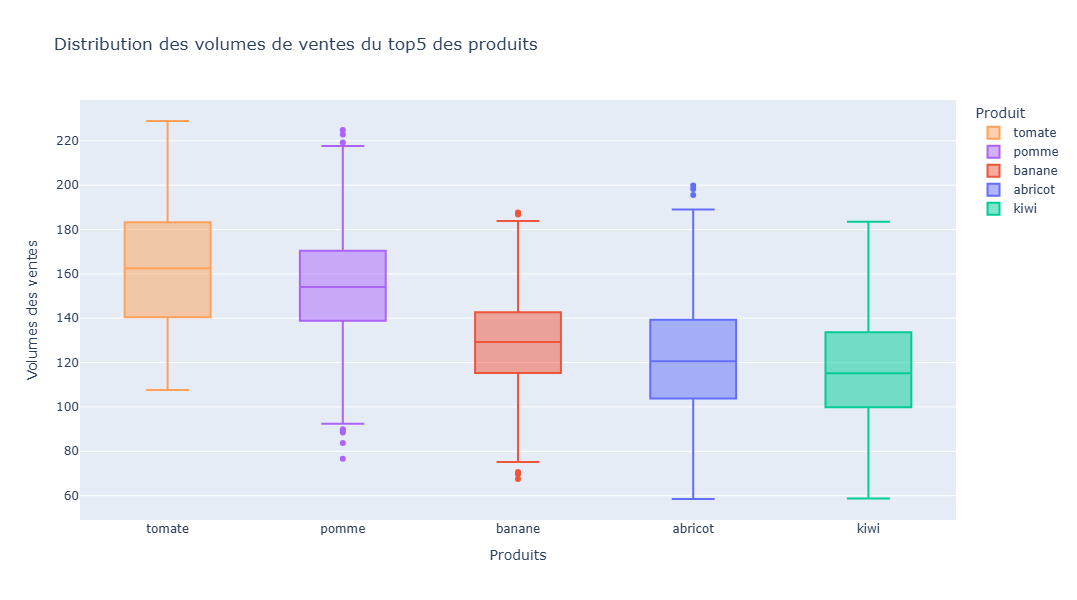

In [137]:
fig=px.box(
data_frame=dataset_top5,
    x="product",
    y="sales",
    color="product",
color_discrete_map={
        "tomate": "#FFA15A",
        "pomme": "#AB63FA",
        "banane": "#EF553B",
        "abricot": "#636EFA",
        "kiwi": "#00CC96"
    },  
    title="Distribution des volumes de ventes du top5 des produits"
)
fig.update_xaxes(
    title_text="Produits"
)
fig.update_yaxes(   
    title_text="Volumes des ventes"
)
fig.update_layout(
    legend_title_text="Produit",
    width=900,
    height=600 
)
fig.show()

Avec une médiane à 162 unité par jour pour la tomate et 154 unités par jour pour la pomme, c'est deux produits ont les volumes quotidien les plus élevès et les autres produits notamment le kiwi à la médiane la plus faible 115 unités par jour.
En calculant IQR, on constate que la tomate présente la plus forte dispersion des volumes quotidien pour ses 50% observations centraux: 43, suivi de l'abricot, IQR= 36 et kiwi (34). La banane présente la distribution la moins dispersée, IQR=27.
Autre observation, pomme, banane et abricot  présentent des  valeurs atypiques visibles au-delà des moustaches, pomme et la banane des deux côtés de leur distribution et pour l'abricot, uniquement la partie haute de la distribution. 

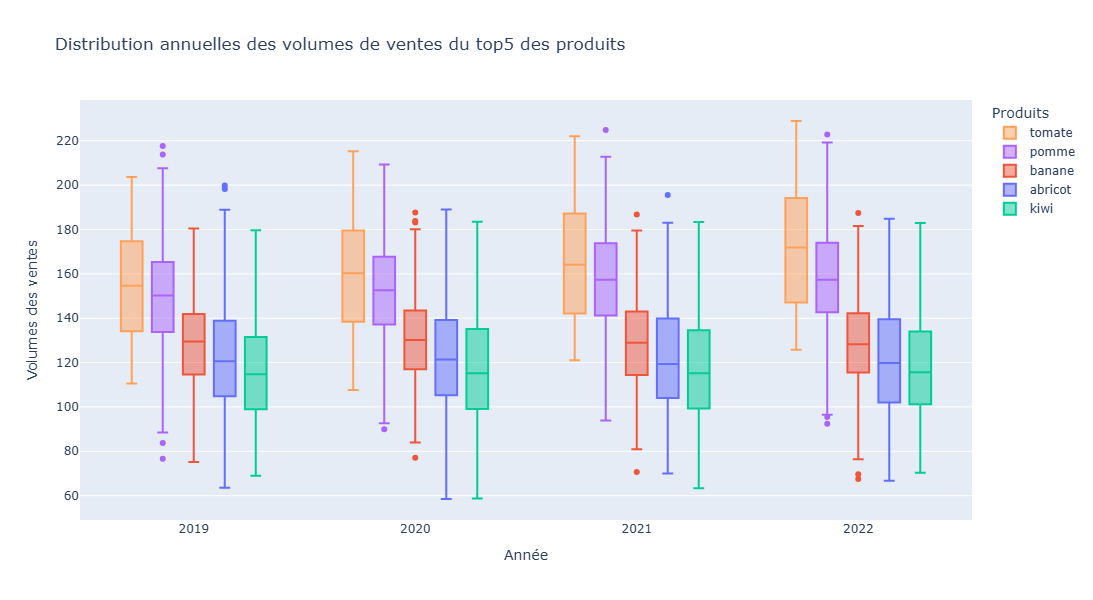

In [138]:
fig=px.box(
data_frame=dataset_top5,
    x="year",
    y="sales",
    color="product",
color_discrete_map={
        "tomate": "#FFA15A",
        "pomme": "#AB63FA",
        "banane": "#EF553B",
        "abricot": "#636EFA",
        "kiwi": "#00CC96"
    },  
    title="Distribution annuelles des volumes de ventes du top5 des produits"
)
fig.update_xaxes(
    title_text="Année"
)
fig.update_yaxes(   
    title_text="Volumes des ventes"
)
fig.update_layout(
    legend_title_text="Produits",
    width=900,
    height=600 
)
fig.show()

1/Premier axe d'analyse:la médiane:
pour la tomate elle passe de 154 unité par jour en 2019 à 171 unités par jour en 2022(évolution progressive)
pour la pomme on passe de 150 en 2019 à 157 unités par jour en 2021 et 2022 (stabilité ces deux dernières années). La banane stabilité sur les 4 ans on passe de 129 à 130 unités entre 2019 et 2020, puis 128 unités par jour en 2021 et 2022. Même observation abricot et kiwi, stabilité sur ces 4 ans (abricot:120, 121,119,119) (kiwi: 114,115,115,115)
2/2nd axe d'analye: la dispersion:
Pour la tomate l'IQR passe de 40, 41, 45, 47 (la dispersion augmente progressivement). Pour la pomme, l'IQR passe de 32,30,32,32(dipersion stable). Pour la banane l'IQR passe de 27,27,29,27(dispersion stable). Pour l'abricot la dispersion passe de 34,34,36,37(légère augmentation). Pour le kiwi la dispersion passe de 33,36,35,32 (stabilité, même si variations observées)
3/3e axe d'analyse: les valeurs atypiques:
Pour la pomme de valeurs atypiques basses et hautes en 2019 et 2022 mais uniquement hautes ou basses en 2020 et 2021. Pour la banane on retrouve également des valeurs atypiques basses et hautes de 2020 à 2022.Pour l'abricot, des valeurs atypiques hautes en 2019 et 2021. A l'inverse de tous les autres produits, la tomate et le kiwi ne présentent aucune valeurs atypiques sur les 4 années. 

### 3.2 Distribution mensuelles des volumes de ventes des top 5 produits
Pour l'analyse mensuelle des distributions, ici les données des 4 années sont regroupés sur 12 mois. Je regroupe tous les mois de janvier ensemble, tous les mois de février ensemble et ainsi de suite. On peut donc comparer pour chaque mois, la médiane, la dispersion (IQR) et les valeurs atypiques. Pour une meilleur lisibilité, on analyse chaque produit séparément.

In [140]:
#avant de construire ces graphiques je construis les tableaux intermédiaires (sous dataframmes)
tomate_mois = dataset_top5[dataset_top5["product"] == "tomate"]
pomme_mois = dataset_top5[dataset_top5["product"] == "pomme"]
banane_mois = dataset_top5[dataset_top5["product"] == "banane"]
abricot_mois = dataset_top5[dataset_top5["product"] == "abricot"]
kiwi_mois = dataset_top5[dataset_top5["product"] == "kiwi"]

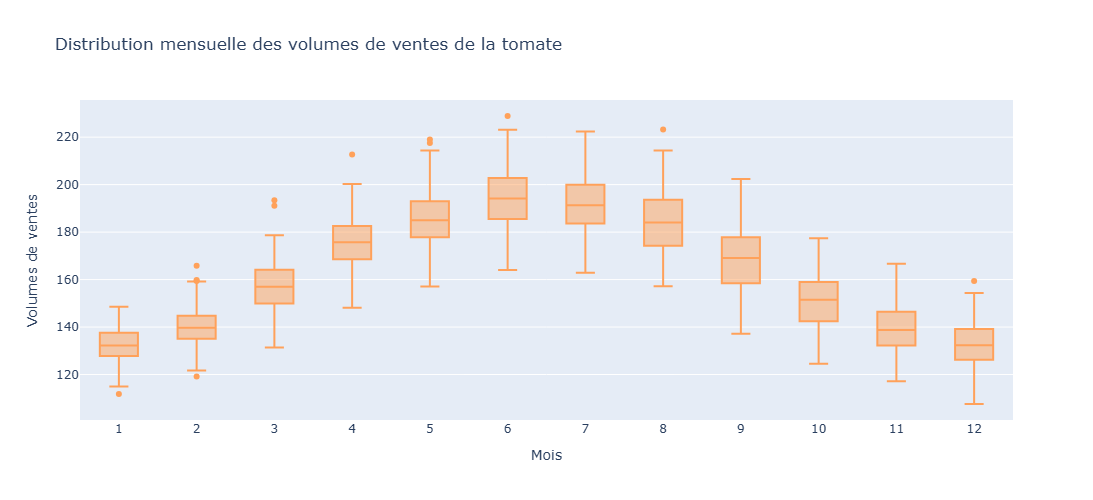

In [146]:
fig = px.box(
    data_frame=tomate_mois,
    x="month",
    y="sales",
    color_discrete_sequence=["#FFA15A"],
    title="Distribution mensuelle des volumes de ventes de la tomate"
)
fig.update_xaxes(
    title_text="Mois",
    tickvals=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    width=1000,
    height=500
)
fig.show()

Les médianes augmentent progressivement de janvier à juin, puis diminuent jusqu'à décembre. Les dispersions varient selon les mois et quelques valeurs atypiques sont observées, notamment au printemps et en été.

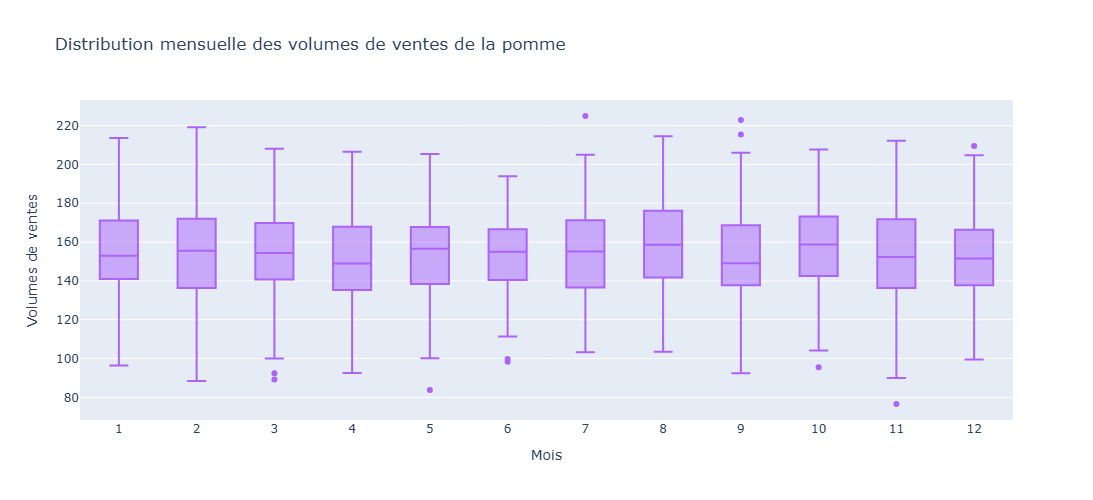

In [142]:
fig = px.box(
    data_frame=pomme_mois,
    x="month",
    y="sales",
    color_discrete_sequence=["#AB63FA"],
    title="Distribution mensuelle des volumes de ventes de la pomme"
)
fig.update_xaxes(
    title_text="Mois",
    tickvals=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    width=1000,
    height=500
)
fig.show()

Les médianes restent proches tout au long de l'année, autour de 150–160. Les dispersions sont assez importantes selon les mois et plusieurs valeurs atypiques sont visibles.

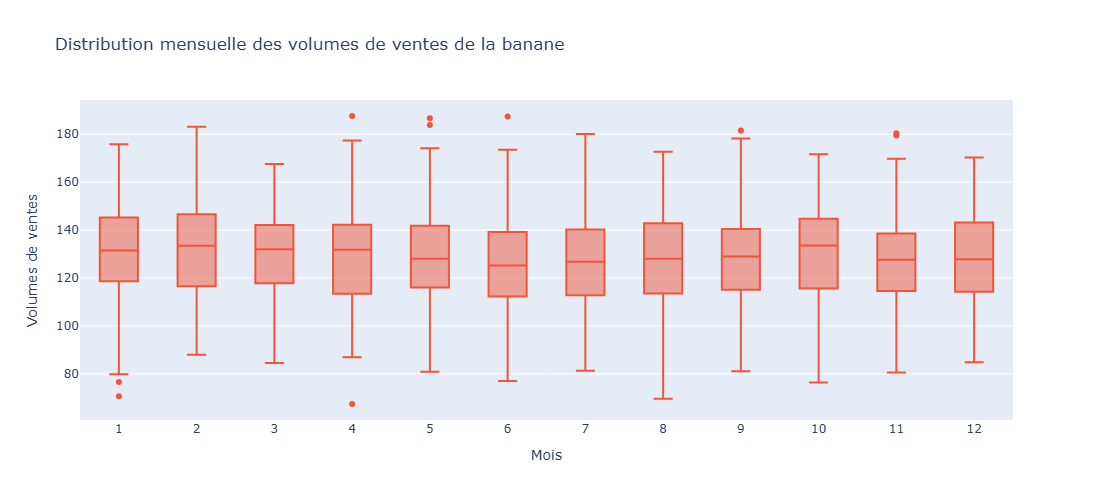

In [143]:
fig = px.box(
    data_frame=banane_mois,
    x="month",
    y="sales",
    color_discrete_sequence=["#EF553B"],
    title="Distribution mensuelle des volumes de ventes de la banane"
)
fig.update_xaxes(
    title_text="Mois",
    tickvals=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    width=1000,
    height=500
)
fig.show()

Les médianes restent assez stables au cours de l'année, autour de 125–135. Les IQR sont également assez proches d'un mois à l'autre, avec quelques valeurs atypiques.

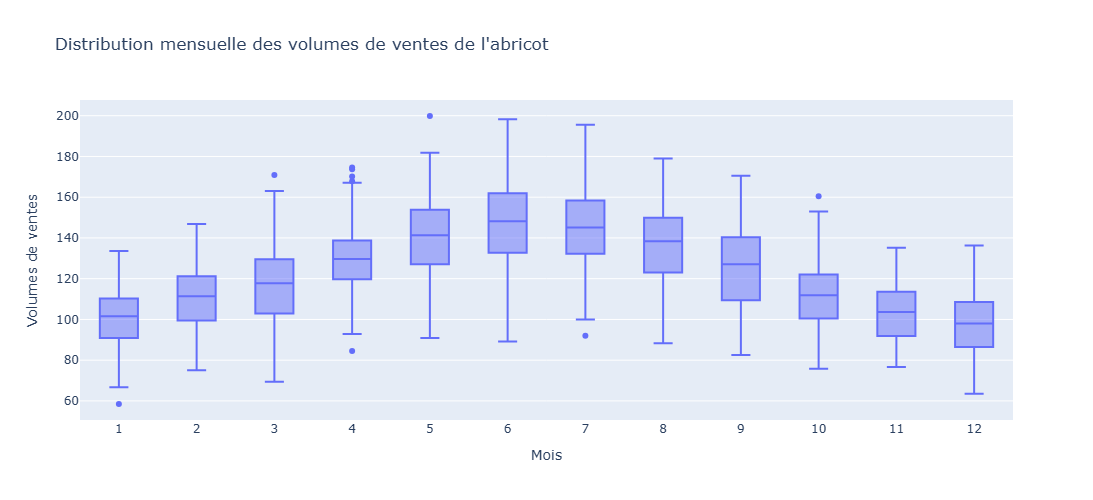

In [144]:
fig = px.box(
    data_frame=abricot_mois,
    x="month",
    y="sales",
    color_discrete_sequence=["#636EFA"],
    title="Distribution mensuelle des volumes de ventes de l'abricot"
)
fig.update_xaxes(
    title_text="Mois",
    tickvals=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    width=1000,
    height=500
)
fig.show()

Les médianes augmentent progressivement jusqu'à juin, puis diminue jusqu'à décembre. Les dispersions varie selon les mois et quelques valeurs atypiques apparaissent, notamment entre mars et mai.

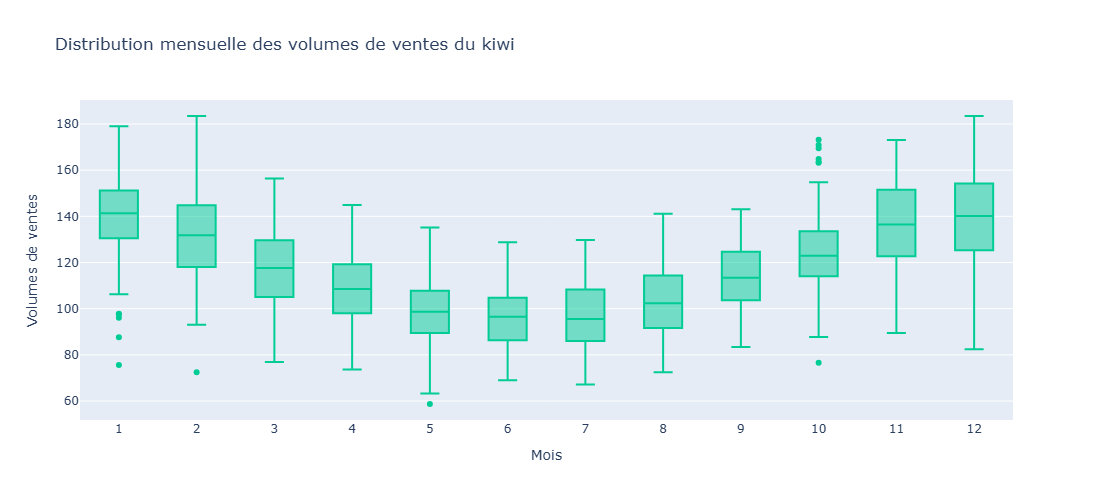

In [145]:
fig = px.box(
    data_frame=kiwi_mois,
    x="month",
    y="sales",
    color_discrete_sequence=["#00CC96"],
    title="Distribution mensuelle des volumes de ventes du kiwi"
)
fig.update_xaxes(
    title_text="Mois",
    tickvals=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
)
fig.update_yaxes(
    title_text="Volumes de ventes"
)
fig.update_layout(
    width=1000,
    height=500
)
fig.show()

Les médianes diminuent progressivement de janvier jusqu'à juin-juillet, puis augmentent jusqu'à décembre. Les dispersions varient selon les mois et plusieurs valeurs atypiques sont visibles, notamment en janvier, février et octobre.

### 3.3 Analysez les corrélations

In [147]:
top5_correlation = top5_mensuel.pivot(
    index="month_year",
    columns="product",
    values="sales"
)
display(top5_correlation.head(10))

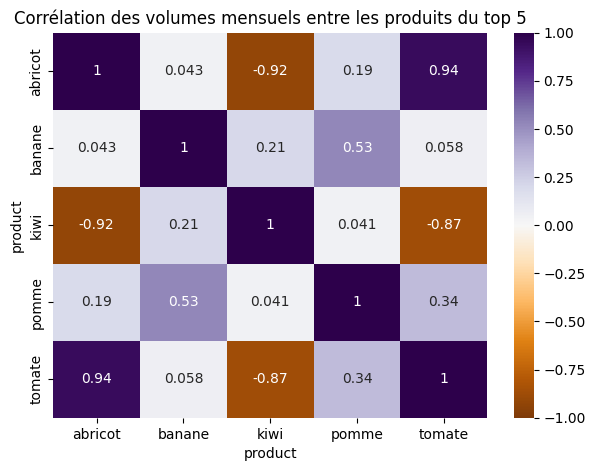

In [183]:
correlation_pearson = top5_correlation.corr(method="pearson")
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_pearson,
    annot=True,
    vmin=-1,
    vmax=1,
    cmap="PuOr"
)
plt.title("Corrélation des volumes mensuels entre les produits du top 5")
plt.show()

La matrice de corrélation montre que la tomate et l’abricot présentent une forte relation positive (0,94) : leurs volumes de ventes évoluent donc généralement dans le même sens. À l’inverse, le kiwi présente une forte relation négative avec l’abricot (-0,92) et la tomate (-0,87), ce qui signifie que leurs volumes évoluent généralement en sens opposé. Enfin, la pomme présente des relations positives plus modérées avec la banane (0,53) et la tomate (0,34). Les autre relations sont plus faibles ou proches de zéro, les volumes de ventes sont moins liées. 

### 3.4 Graphiques complémentaires
Pour compléter l'analyse des corrélations, les évolutions mensuelles des produits sont comparées 2 par 2 pour vérifier visuellement si leurs pics et leurs creux appraisent aux mêmes périodes. 

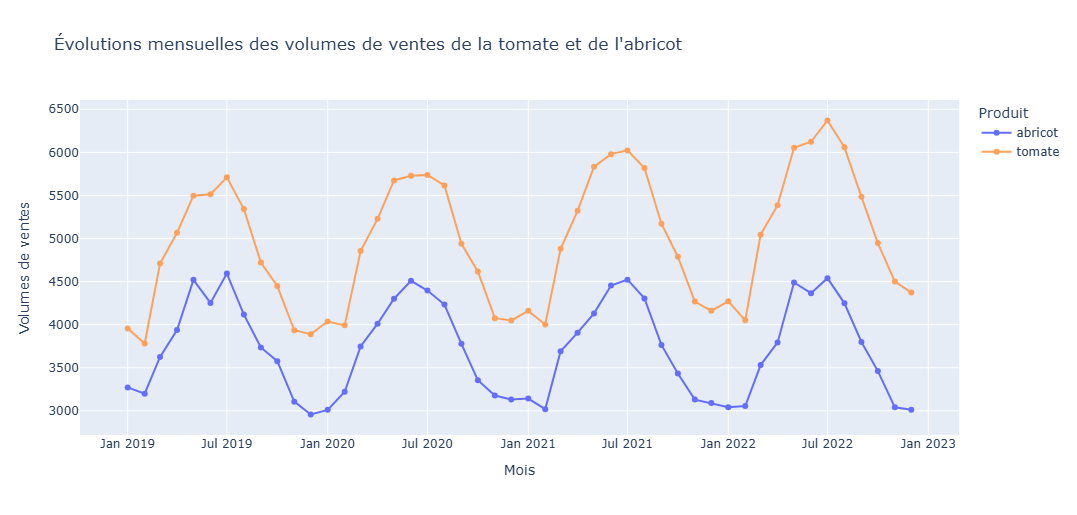

In [184]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"].isin(["tomate", "abricot"])],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_map={
        "tomate": "#FFA15A",
        "abricot": "#636EFA"
    },
    title="Évolutions mensuelles des volumes de ventes de la tomate et de l'abricot"
)
fig.update_xaxes(title_text="Mois")
fig.update_yaxes(title_text="Volumes de ventes")
fig.update_layout(
    legend_title_text="Produit",
    width=1100,
    height=500
)
fig.show()

Ces deux produits tomate/abricot évoluent dans le même sens-corrélation positive et forte(0,94)

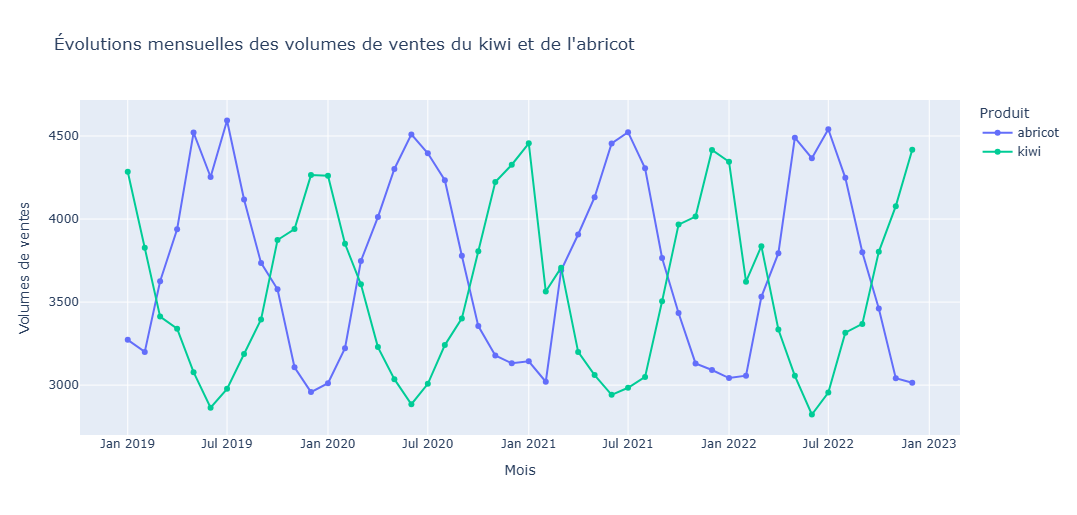

In [185]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"].isin(["kiwi", "abricot"])],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_map={
        "kiwi": "#00CC96",
        "abricot": "#636EFA"
    },
    title="Évolutions mensuelles des volumes de ventes du kiwi et de l'abricot"
)
fig.update_xaxes(title_text="Mois")
fig.update_yaxes(title_text="Volumes de ventes")
fig.update_layout(
    legend_title_text="Produit",
    width=1100,
    height=500
)
fig.show()

Evolutions opposées, lorsque les volumes de l'abricot augementent ceux du kiwi ont tendance à diminuer et inversement-corrélation négative et forte(-0,92).

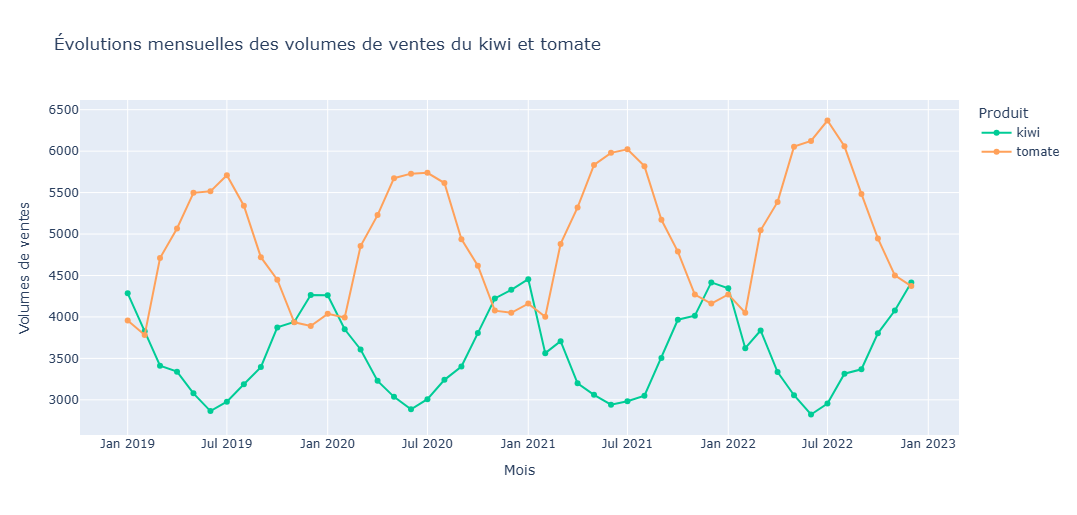

In [186]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"].isin(["kiwi", "tomate"])],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_map={
        "kiwi": "#00CC96",
        "tomate": "#FFA15A"
    },
    title="Évolutions mensuelles des volumes de ventes du kiwi et tomate"
)
fig.update_xaxes(title_text="Mois")
fig.update_yaxes(title_text="Volumes de ventes")
fig.update_layout(
    legend_title_text="Produit",
    width=1100,
    height=500
)
fig.show()

Evolutions opposées également pour ce duo de produits, forte corrélation négative(-0,87).

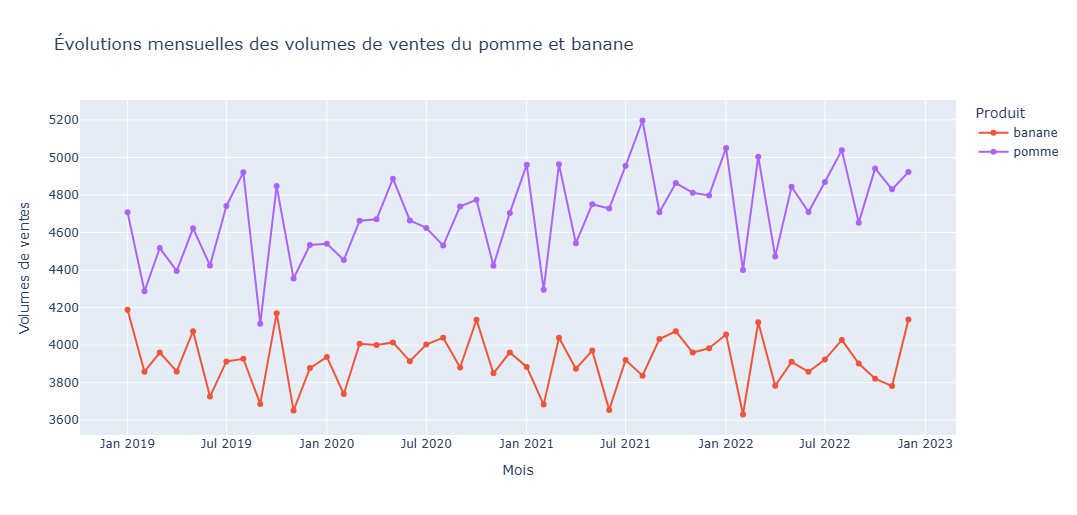

In [187]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"].isin(["pomme", "banane"])],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_map={
        "pomme": "#AB63FA",
        "banane": "#EF553B"
    },
    title="Évolutions mensuelles des volumes de ventes du pomme et banane"
)
fig.update_xaxes(title_text="Mois")
fig.update_yaxes(title_text="Volumes de ventes")
fig.update_layout(
    legend_title_text="Produit",
    width=1100,
    height=500
)
fig.show()

Les courbes du duo pomme/banane ne suivent pas toujours la même évolution, relation positive mais modérée (0,53).

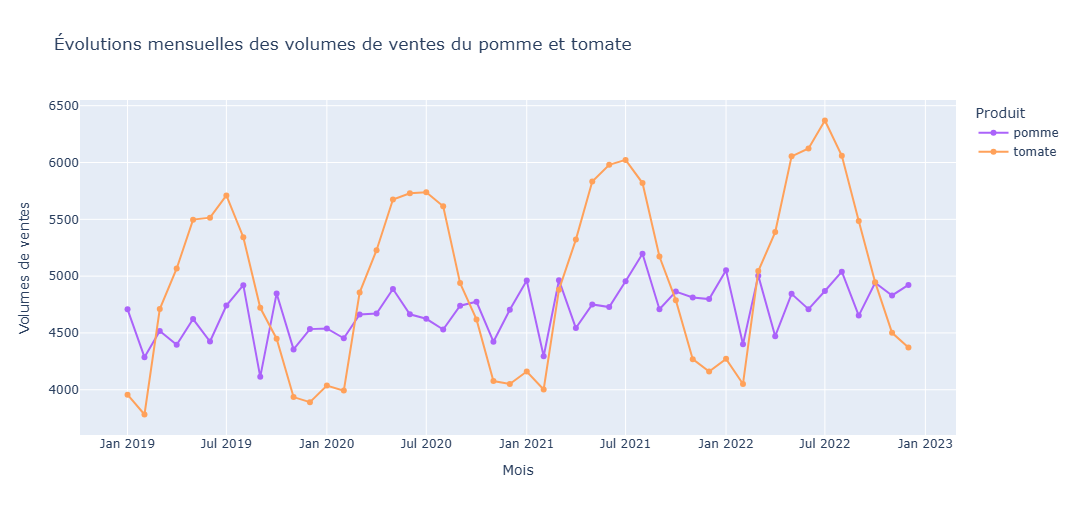

In [188]:
fig = px.line(
    top5_mensuel[top5_mensuel["product"].isin(["pomme", "tomate"])],
    x="month_year",
    y="sales",
    color="product",
    markers=True,
    color_discrete_map={
        "pomme": "#AB63FA",
        "tomate": "#FFA15A"
    },
    title="Évolutions mensuelles des volumes de ventes du pomme et tomate"
)
fig.update_xaxes(title_text="Mois")
fig.update_yaxes(title_text="Volumes de ventes")
fig.update_layout(
    legend_title_text="Produit",
    width=1100,
    height=500
)
fig.show()

Quelques évolutions dans le même sens pour ce duo de produits mais moins régulière-corrélation positive plus faible(0,34)

### 3.5 Conclusion et recommandations de répartition en entrepôt

##### Quels produits du top 5 présentent des comportements de vente similaires au cours de l’année afin d’optimiser leur répartition dans l’entrepôt ?
Principalement la tomate et l’abricot. La pomme et la banane présentent également certaines similitudes, mais moins marquée. À l’inverse, le kiwi présente une saisonnalité opposée à celle de la tomate et de l’abricot.
##### Recommandations: 
Placer la tomate et l'abricot dans des zones  proches car périodes de forte demande similaires et en plus c'est facile pour la préparation des commandes et le réapprovisionnement. Pomme et tomate pourraient également être rapprochées même si les comportement de ventes moins fortement similaires. Placer kiwi et tomate ainsi que kiwi et abricot dans des zones différentes. 